# L1 and L2 Regularisation in Neural Networks

A teaching notebook. A regulariser adds a penalty on the weights to the loss, so the network cannot freely use large (or many) weights to fit noise.

$$\text{L2:}\quad L = \mathrm{MSE} + \lambda \sum_i w_i^2 \qquad\qquad \text{L1:}\quad L = \mathrm{MSE} + \lambda \sum_i |w_i|$$

(The penalty is applied to weight matrices only, not to biases, which is the usual convention.)

| # | Experiment | Question it answers |
|---|---|---|
| 1 | Geometry | What does each penalty do to a single weight, and to a pair of weights? |
| 2 | Overfitting and the effect of `lambda` | Do L1 and L2 reduce test error, and what happens if `lambda` is too large? |
| 3 | What happens to the weights | Shrinkage (L2) vs sparsity (L1): norms and histograms |
| 4 | Does L1 give exact zeros? | Why the **optimizer** changes the answer (Adam, SGD, proximal) |
| 5 | Feature selection | Can an L1 penalty on the first layer find the useful inputs? |
| 6 | L2 vs weight decay | When are they the same thing, and when not (Adam vs AdamW)? |
| 7 | Practical notes | How to use these correctly |

Throughout, `lambda` is chosen on a **validation set** and results are reported on a separate **test set**. Runs on CPU in several minutes.

In [1]:
import math, time, functools
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(2)
print("torch", torch.__version__)

torch 2.15.0+cu132


## Experiment 1: what each penalty does (geometry)

**Gradient view.** Adding the penalty changes each weight's gradient:

- L2: `d/dw (lambda w^2) = 2 lambda w`. The pull toward zero is **proportional to the weight**, so it fades as the weight gets small. One SGD step multiplies the weight by `(1 - 2 eta lambda)`, which is why L2 is called *weight decay*.
- L1: `d/dw (lambda |w|) = lambda sign(w)`. The pull is a **constant size**, no matter how small the weight is, so it can push a weight all the way to zero and hold it there.

**One weight.** Suppose the loss alone would put a weight at `w0`: `loss = 0.5 (w - w0)^2`. The penalised optimum has a closed form: L2 gives `w0 / (1 + 2 lambda)` (scale it down), L1 gives `sign(w0) max(|w0| - lambda, 0)` (subtract, and **clip to exactly zero**, called soft-thresholding).

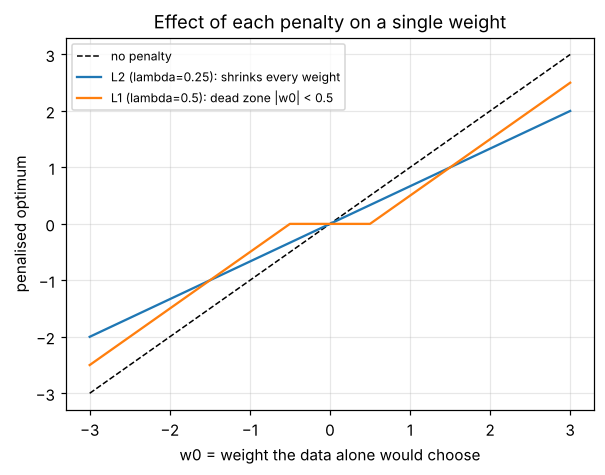

In [2]:
w0s = np.linspace(-3, 3, 301)
lam2, lam1 = 0.25, 0.5
l2_sol = w0s / (1 + 2 * lam2)
l1_sol = np.sign(w0s) * np.maximum(np.abs(w0s) - lam1, 0)

plt.figure(figsize=(6.2, 4.4))
plt.plot(w0s, w0s, "k--", lw=1, label="no penalty")
plt.plot(w0s, l2_sol, label=f"L2 (lambda={lam2}): shrinks every weight")
plt.plot(w0s, l1_sol, label=f"L1 (lambda={lam1}): dead zone |w0| < {lam1}")
plt.xlabel("w0 = weight the data alone would choose"); plt.ylabel("penalised optimum")
plt.title("Effect of each penalty on a single weight"); plt.legend(fontsize=8); plt.show()

**Two weights.** The loss `L(w) = 0.5 (w - w0)^T A (w - w0)` has elliptical contours centred on `w0 = (2.0, 0.8)`, with correlated coordinates. As `lambda` grows from 0, we trace the penalised optimum. The classic picture: the optimum is where a loss contour touches the **norm ball** through it, which is a circle for L2 and a **diamond** for L1. The diamond has corners on the axes, so the touching point tends to land on an axis, which means one weight is exactly zero.

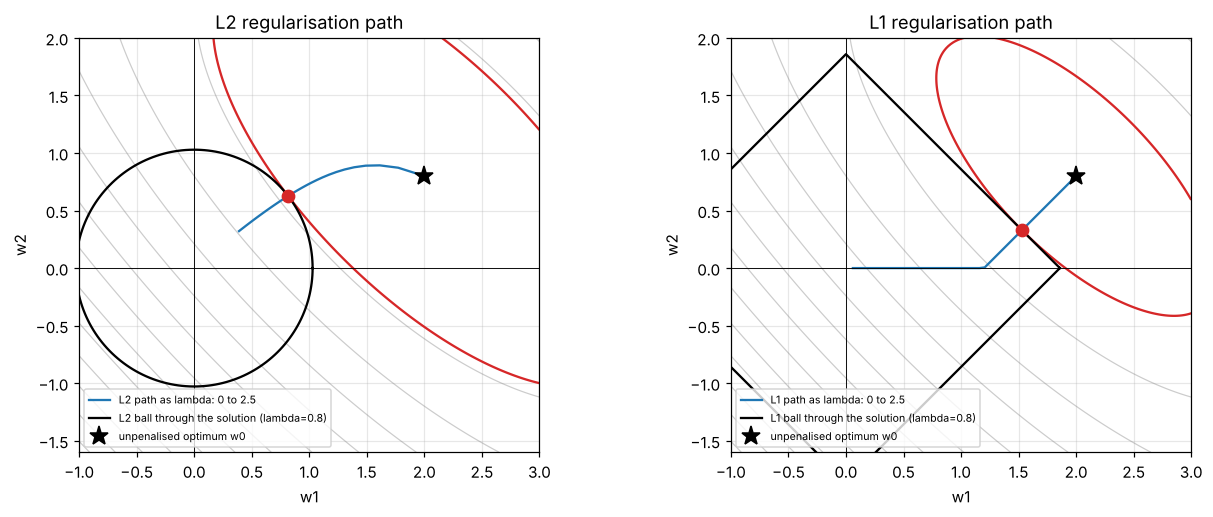

L1: w2 becomes exactly 0 from lambda = 1.40 onward (w1 is still 1.16)
L2: smallest |w2| along the path = 0.321 (never exactly 0 for finite lambda)
lambda=0.0   L2 -> [2.  0.8]   L1 -> [2.  0.8]
lambda=0.3   L2 -> [1.235 0.835]   L1 -> [1.824 0.624]
lambda=0.8   L2 -> [0.816 0.626]   L1 -> [1.529 0.329]
lambda=1.5   L2 -> [0.561 0.452]   L1 -> [1.06 0.  ]


In [3]:
A = np.array([[1.0, 0.7], [0.7, 1.0]]); w0 = np.array([2.0, 0.8])
loss2d = lambda w: 0.5 * (w - w0) @ A @ (w - w0)

def sol_l2(lam):                                  # penalty lam * ||w||^2 (closed form)
    return np.linalg.solve(A + 2 * lam * np.eye(2), A @ w0)

def sol_l1(lam, iters=2000):                      # penalty lam * ||w||_1 (proximal gradient)
    L = np.linalg.eigvalsh(A).max(); w = w0.copy()
    for _ in range(iters):
        w = w - A @ (w - w0) / L
        w = np.sign(w) * np.maximum(np.abs(w) - lam / L, 0)
    return w

lams = np.linspace(0, 2.5, 51)
P2 = np.array([sol_l2(l) for l in lams]); P1 = np.array([sol_l1(l) for l in lams])
LAM_SHOW = 0.8

g1, g2 = np.meshgrid(np.linspace(-1, 3, 200), np.linspace(-1.6, 2, 200))
Lg = np.array([[loss2d(np.array([a, b])) for a in g1[0]] for b in g2[:, 0]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, P, sol, name in ((axes[0], P2, sol_l2, "L2"), (axes[1], P1, sol_l1, "L1")):
    ax.contour(g1, g2, Lg, levels=12, colors="gray", alpha=0.4, linewidths=0.8)
    ax.plot(*P.T, "-", color="tab:blue", label=f"{name} path as lambda: 0 to {lams[-1]}")
    ws = sol(LAM_SHOW)
    ax.contour(g1, g2, Lg, levels=[loss2d(ws)], colors="tab:red", linewidths=1.5)
    if name == "L2":
        r = np.linalg.norm(ws, 2); th = np.linspace(0, 2 * np.pi, 200)
        ax.plot(r * np.cos(th), r * np.sin(th), "k-", lw=1.5, label=f"L2 ball through the solution (lambda={LAM_SHOW})")
    else:
        r = np.abs(ws).sum()
        ax.plot([r, 0, -r, 0, r], [0, r, 0, -r, 0], "k-", lw=1.5, label=f"L1 ball through the solution (lambda={LAM_SHOW})")
    ax.plot(*ws, "o", color="tab:red", ms=8, zorder=5); ax.plot(*w0, "k*", ms=13, label="unpenalised optimum w0")
    ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
    ax.set_xlim(-1, 3); ax.set_ylim(-1.6, 2); ax.set_aspect("equal"); ax.set_xlabel("w1"); ax.set_ylabel("w2")
    ax.set_title(f"{name} regularisation path"); ax.legend(fontsize=7, loc="lower left")
plt.tight_layout(); plt.show()

first0 = lams[np.argmax(np.abs(P1[:, 1]) < 1e-9)]
print(f"L1: w2 becomes exactly 0 from lambda = {first0:.2f} onward (w1 is still {P1[np.argmax(np.abs(P1[:, 1]) < 1e-9), 0]:.2f})")
print(f"L2: smallest |w2| along the path = {np.abs(P2[:, 1]).min():.3f} (never exactly 0 for finite lambda)")
for l in (0.0, 0.3, 0.8, 1.5):
    print(f"lambda={l:<4}  L2 -> {np.round(sol_l2(l), 3)}   L1 -> {np.round(sol_l1(l), 3)}")

## Experiment 2: overfitting and the effect of `lambda`

Task: fit `y = sin(x) + noise` (noise std 0.3, so the **best possible test MSE is about 0.09**) from only **30 training points**, with a 2-hidden-layer tanh MLP (64 units each) that has enough capacity to memorise them.

- `lambda` is picked on a separate **validation** set (200 points), then performance is reported on a **test** set (500 points).
- Optimizer: Adam, 3000 full-batch steps. The penalty is added to the loss.
- 5 seeds (different data draws and initialisations), mean and standard deviation shown.

In [4]:
def mlp(d_in=1, h=64, depth=2):
    layers, d = [], d_in
    for _ in range(depth):
        layers += [nn.Linear(d, h), nn.Tanh()]; d = h
    return nn.Sequential(*layers, nn.Linear(d, 1))

def linear_weights(net):
    return [m.weight for m in net if isinstance(m, nn.Linear)]       # weights only, no biases

def weight_vector(net):
    return torch.cat([w.detach().flatten() for w in linear_weights(net)])

def penalty(net, kind):
    ws = linear_weights(net)
    return sum((w ** 2).sum() for w in ws) if kind == "l2" else sum(w.abs().sum() for w in ws)

@functools.lru_cache(maxsize=None)
def reg_data(seed, n=30, noise=0.3, n_val=200, n_test=500):
    g = torch.Generator().manual_seed(seed)
    x = torch.rand(n, 1, generator=g) * 6 - 3
    y = torch.sin(x) + noise * torch.randn(n, 1, generator=g)
    g2 = torch.Generator().manual_seed(10_000 + seed)
    xv = torch.rand(n_val, 1, generator=g2) * 6 - 3
    yv = torch.sin(xv) + noise * torch.randn(n_val, 1, generator=g2)
    xt = torch.linspace(-3, 3, n_test).unsqueeze(1)
    yt = torch.sin(xt) + noise * torch.randn(n_test, 1, generator=g2)
    return dict(x=x, y=y, xv=xv, yv=yv, xt=xt, yt=yt)

OPT_CFG = {"adam": dict(epochs=3000), "sgd": dict(epochs=6000), "prox": dict(epochs=6000)}

def fit_reg(opt_name, kind, lam, seed):
    """opt_name: 'adam' | 'sgd' (momentum 0.9) | 'prox' (plain GD + soft-threshold, L1 only)."""
    d = reg_data(seed)
    torch.manual_seed(seed)
    net = mlp()
    if opt_name == "adam":
        opt = torch.optim.Adam(net.parameters(), lr=1e-2)
    elif opt_name == "sgd":
        opt = torch.optim.SGD(net.parameters(), lr=1e-2, momentum=0.9)
    else:
        opt = torch.optim.SGD(net.parameters(), lr=1e-2)
    lr = opt.param_groups[0]["lr"]
    for _ in range(OPT_CFG[opt_name]["epochs"]):
        opt.zero_grad()
        loss = F.mse_loss(net(d["x"]), d["y"])
        if lam > 0 and opt_name != "prox":
            loss = loss + lam * penalty(net, kind)
        loss.backward(); opt.step()
        if opt_name == "prox" and lam > 0:                      # proximal step for the L1 term
            with torch.no_grad():
                for w in linear_weights(net):
                    w.copy_(torch.sign(w) * torch.clamp(w.abs() - lr * lam, min=0))
    with torch.no_grad():
        mse = lambda a, b: F.mse_loss(net(a), b).item()
        return dict(net=net, train=mse(d["x"], d["y"]), val=mse(d["xv"], d["yv"]), test=mse(d["xt"], d["yt"]))

In [5]:
SEEDS = range(5)
GRID = {"l2": [1e-5, 1e-4, 1e-3, 1e-2, 1e-1], "l1": [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]}

t0 = time.time()
base = [fit_reg("adam", None, 0.0, s) for s in SEEDS]
sweep = {(k, lam): [fit_reg("adam", k, lam, s) for s in SEEDS] for k in GRID for lam in GRID[k]}
print(f"({time.time()-t0:.0f}s)")

stat = lambda rs, key: (np.mean([r[key] for r in rs]), np.std([r[key] for r in rs]))
print(f"{'':>10s} {'lambda':>8s} | {'train MSE':>10s} | {'val MSE':>10s} | {'test MSE':>16s}")
a, b, c = stat(base, "train"), stat(base, "val"), stat(base, "test")
print(f"{'none':>10s} {0:>8g} | {a[0]:>10.4f} | {b[0]:>10.4f} | {c[0]:>8.4f} +- {c[1]:.3f}")
best = {}
for k in GRID:
    best[k] = min(GRID[k], key=lambda lam: stat(sweep[(k, lam)], "val")[0])
    for lam in GRID[k]:
        rs = sweep[(k, lam)]; a, b, c = stat(rs, "train"), stat(rs, "val"), stat(rs, "test")
        mark = "  <- best on validation" if lam == best[k] else ""
        print(f"{k.upper():>10s} {lam:>8g} | {a[0]:>10.4f} | {b[0]:>10.4f} | {c[0]:>8.4f} +- {c[1]:.3f}{mark}")
print("noise floor (best possible test MSE) ~ 0.09")

(99s)
             lambda |  train MSE |    val MSE |         test MSE
      none        0 |     0.0102 |     0.2896 |   0.2827 +- 0.082
        L2    1e-05 |     0.0121 |     0.2728 |   0.2736 +- 0.090
        L2   0.0001 |     0.0202 |     0.2203 |   0.2181 +- 0.058
        L2    0.001 |     0.0549 |     0.1135 |   0.1086 +- 0.015
        L2     0.01 |     0.0821 |     0.1071 |   0.1079 +- 0.014  <- best on validation
        L2      0.1 |     0.1929 |     0.2211 |   0.2220 +- 0.018
        L1    1e-05 |     0.0124 |     0.2287 |   0.2350 +- 0.063
        L1   0.0001 |     0.0210 |     0.2051 |   0.2070 +- 0.054
        L1    0.001 |     0.0546 |     0.1265 |   0.1198 +- 0.026  <- best on validation
        L1     0.01 |     0.1211 |     0.1407 |   0.1413 +- 0.008
        L1      0.1 |     0.1499 |     0.1731 |   0.1729 +- 0.015
noise floor (best possible test MSE) ~ 0.09


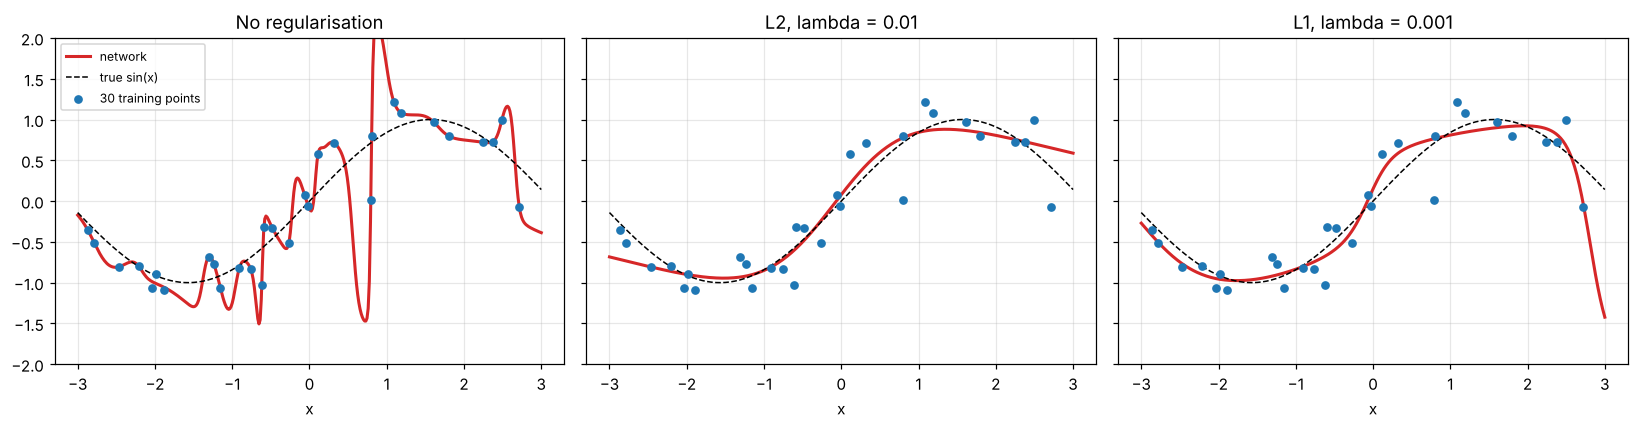

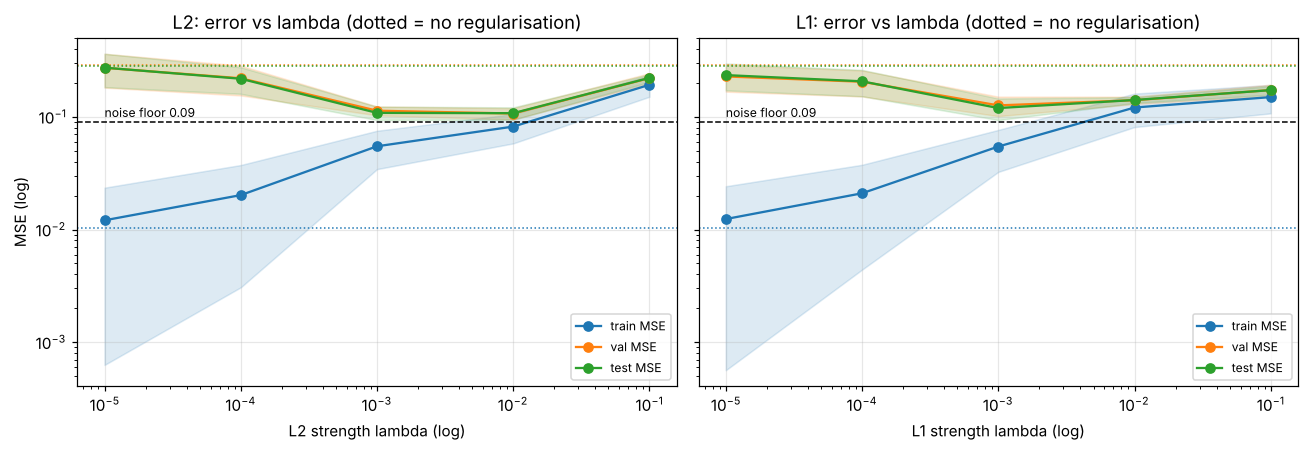

In [6]:
d0 = reg_data(0)
xg = torch.linspace(-3, 3, 400).unsqueeze(1)
panels = [("No regularisation", base[0]["net"]),
          (f"L2, lambda = {best['l2']:g}", sweep[("l2", best["l2"])][0]["net"]),
          (f"L1, lambda = {best['l1']:g}", sweep[("l1", best["l1"])][0]["net"])]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (title, net) in zip(axes, panels):
    with torch.no_grad():
        ax.plot(xg, net(xg), color="tab:red", lw=2, label="network")
    ax.plot(xg, torch.sin(xg), "k--", lw=1, label="true sin(x)")
    ax.scatter(d0["x"], d0["y"], s=22, color="tab:blue", zorder=3, label="30 training points")
    ax.set_title(title); ax.set_xlabel("x"); ax.set_ylim(-2, 2)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, k in zip(axes, ("l2", "l1")):
    lams = GRID[k]
    for key, color in (("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")):
        m = np.array([stat(sweep[(k, lam)], key)[0] for lam in lams])
        sd = np.array([stat(sweep[(k, lam)], key)[1] for lam in lams])
        ax.plot(lams, m, "o-", color=color, label=f"{key} MSE"); ax.fill_between(lams, m - sd, m + sd, color=color, alpha=0.15)
        ax.axhline(stat(base, key)[0], color=color, ls=":", lw=1)
    ax.axhline(0.09, color="k", ls="--", lw=1); ax.text(lams[0], 0.1, "noise floor 0.09", fontsize=8)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(f"{k.upper()} strength lambda (log)")
    ax.set_title(f"{k.upper()}: error vs lambda (dotted = no regularisation)"); ax.legend(fontsize=8)
axes[0].set_ylabel("MSE (log)")
plt.tight_layout(); plt.show()

## Experiment 3: what happens to the weights

Use the seed-0 networks from Experiment 2. We look at the weight norms as `lambda` grows, and at the full weight histogram for the unregularised net and the validation-chosen L2 and L1 nets. "Tiny" below means `|w| < 1e-3`.

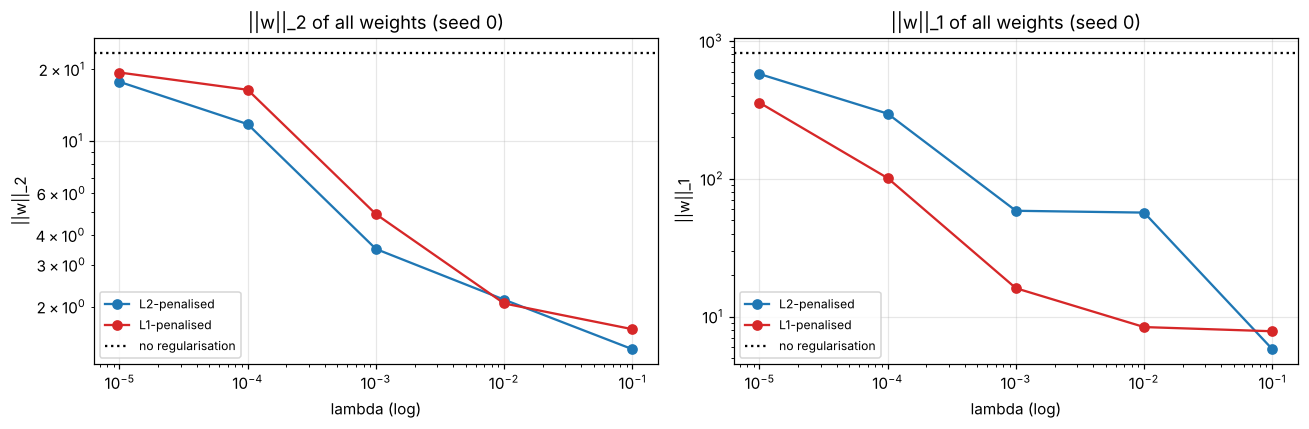

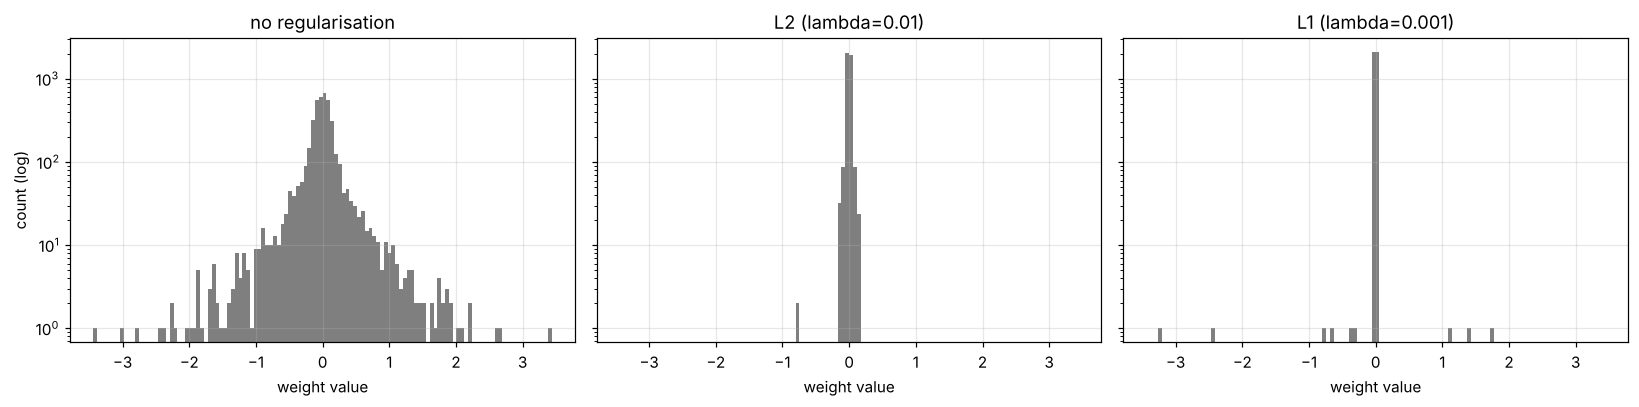

                   network |  ||w||_2 |   ||w||_1 |  |w|<1e-3 |  |w|<1e-2 | exactly 0
         no regularisation |    23.48 |     822.5 |      0.6% |      5.0% |      0.0%
          L2 (lambda=0.01) |     2.14 |      56.9 |      8.9% |     94.4% |      0.0%
         L1 (lambda=0.001) |     4.91 |      16.1 |     60.7% |     99.8% |      0.0%


In [7]:
def wstats(net):
    w = weight_vector(net)
    return dict(l2=w.norm().item(), l1=w.abs().sum().item(), tiny=(w.abs() < 1e-3).float().mean().item(),
                small=(w.abs() < 1e-2).float().mean().item(), zero=(w == 0).float().mean().item(), n=w.numel())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
b0 = wstats(base[0]["net"])
for k, color in (("l2", "tab:blue"), ("l1", "tab:red")):
    st = [wstats(sweep[(k, lam)][0]["net"]) for lam in GRID[k]]
    axes[0].plot(GRID[k], [s["l2"] for s in st], "o-", color=color, label=f"{k.upper()}-penalised")
    axes[1].plot(GRID[k], [s["l1"] for s in st], "o-", color=color, label=f"{k.upper()}-penalised")
for ax, key, name in ((axes[0], "l2", "||w||_2"), (axes[1], "l1", "||w||_1")):
    ax.axhline(b0[key], color="k", ls=":", label="no regularisation")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("lambda (log)"); ax.set_ylabel(name); ax.set_title(f"{name} of all weights (seed 0)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

nets3 = {"no regularisation": base[0]["net"], f"L2 (lambda={best['l2']:g})": sweep[("l2", best["l2"])][0]["net"],
         f"L1 (lambda={best['l1']:g})": sweep[("l1", best["l1"])][0]["net"]}
lim = max(weight_vector(n).abs().max().item() for n in nets3.values())
bins = np.linspace(-lim, lim, 121)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (name, net) in zip(axes, nets3.items()):
    ax.hist(weight_vector(net).numpy(), bins=bins, color="tab:gray"); ax.set_yscale("log")
    ax.set_title(name); ax.set_xlabel("weight value")
axes[0].set_ylabel("count (log)")
plt.tight_layout(); plt.show()

print(f"{'network':>26s} | {'||w||_2':>8s} | {'||w||_1':>9s} | {'|w|<1e-3':>9s} | {'|w|<1e-2':>9s} | {'exactly 0':>9s}")
for name, net in nets3.items():
    s = wstats(net)
    print(f"{name:>26s} | {s['l2']:>8.2f} | {s['l1']:>9.1f} | {100*s['tiny']:>8.1f}% | {100*s['small']:>8.1f}% | {100*s['zero']:>8.1f}%")

## Experiment 4: does L1 give exact zeros? The optimizer matters

The textbook says "L1 produces sparse solutions". Experiment 3 shows many tiny weights but, with Adam, **none are exactly zero**. There are two separate effects:

1. **Exactly zero** requires an update that can land on zero and stay there. A plain (sub)gradient step `w <- w - eta (grad + lambda sign(w))` overshoots zero and then oscillates around it, so weights end up tiny, not zero. A **proximal** step (soft-threshold after each gradient step) clips to exactly zero.
2. **How many weights become tiny** depends on the optimizer and training length, not only on the penalty. A likely reason for Adam (consistent with the results below, though we do not isolate it): Adam divides by a running gradient scale, so even a small penalty gradient can move weights that the data barely uses at close to full learning-rate speed.

To see this, train the same model with three optimizers and compare **test error and sparsity together**. `lambda` values here are fixed (not tuned), 3 seeds, so read the table as a demonstration of behaviour, not as a ranking.

In [8]:
configs = [("Adam", "adam", None, 0.0), ("SGD+momentum", "sgd", None, 0.0),
           ("Adam", "adam", "l2", 1e-3), ("Adam", "adam", "l1", 1e-3),
           ("SGD+momentum", "sgd", "l2", 1e-3), ("SGD+momentum", "sgd", "l2", 1e-2), ("SGD+momentum", "sgd", "l1", 1e-3),
           ("Proximal GD", "prox", "l1", 1e-3), ("Proximal GD", "prox", "l1", 3e-3)]
t0 = time.time()
rows = []
for label, opt_name, kind, lam in configs:
    rs = [fit_reg(opt_name, kind, lam, s) for s in range(3)]
    ws = [wstats(r["net"]) for r in rs]
    rows.append((label, kind, lam, np.mean([r["train"] for r in rs]), np.mean([r["test"] for r in rs]),
                 np.mean([w["l1"] for w in ws]), np.mean([w["tiny"] for w in ws]), np.mean([w["zero"] for w in ws])))
print(f"({time.time()-t0:.0f}s)")
print(f"{'optimizer':>13s} {'penalty':>8s} {'lambda':>7s} | {'train':>6s} | {'test':>6s} | {'||w||_1':>8s} | {'|w|<1e-3':>9s} | {'exactly 0':>9s}")
for label, kind, lam, tr, te, l1n, tiny, zero in rows:
    print(f"{label:>13s} {str(kind).upper() if kind else 'none':>8s} {lam:>7g} | {tr:>6.3f} | {te:>6.3f} | {l1n:>8.1f} | {100*tiny:>8.1f}% | {100*zero:>8.1f}%")

(58s)
    optimizer  penalty  lambda |  train |   test |  ||w||_1 |  |w|<1e-3 | exactly 0
         Adam     none       0 |  0.003 |  0.308 |    852.3 |      0.7% |      0.0%
 SGD+momentum     none       0 |  0.043 |  0.136 |    332.0 |      0.8% |      0.0%
         Adam       L2   0.001 |  0.052 |  0.119 |     79.3 |     54.5% |      0.0%
         Adam       L1   0.001 |  0.052 |  0.137 |     18.5 |     58.7% |      0.0%
 SGD+momentum       L2   0.001 |  0.062 |  0.106 |    133.9 |      2.6% |      0.0%
 SGD+momentum       L2    0.01 |  0.084 |  0.117 |     46.1 |     45.7% |      0.0%
 SGD+momentum       L1   0.001 |  0.062 |  0.109 |     23.2 |     98.5% |      0.0%
  Proximal GD       L1   0.001 |  0.076 |  0.107 |    111.9 |     47.1% |     46.2%
  Proximal GD       L1   0.003 |  0.085 |  0.122 |     33.7 |     94.8% |     94.6%


## Experiment 5: L1 as feature selection

Setup: 20 input features, but the target depends on only **3** of them (`y = 2 x0 - 1.5 x1 + sin(2 x2) + noise`); the other 17 are pure noise. Only 100 training points, so a network with a free first layer can fit noise through the irrelevant inputs.

We penalise **only the first layer** (the weights attached to the inputs) and score each input by the L1 norm of its column of first-layer weights. A good selector gives the 3 true features large scores and the 17 noise features small ones. `lambda` is chosen on a validation set (300 points) per penalty type; 5 seeds.

In [9]:
@functools.lru_cache(maxsize=None)
def feat_data(seed, n=100, d=20, n_val=300, n_test=1000):
    g = torch.Generator().manual_seed(seed)
    f = lambda x: (2 * x[:, 0] - 1.5 * x[:, 1] + torch.sin(2 * x[:, 2])).unsqueeze(1)
    mk = lambda m: (lambda x: (x, f(x) + 0.3 * torch.randn(m, 1, generator=g)))(torch.randn(m, d, generator=g))
    (x, y), (xv, yv), (xt, yt) = mk(n), mk(n_val), mk(n_test)
    return dict(x=x, y=y, xv=xv, yv=yv, xt=xt, yt=yt)

def fit_feat(kind, lam, seed, epochs=3000):
    d = feat_data(seed); torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(20, 32), nn.Tanh(), nn.Linear(32, 1))
    opt = torch.optim.Adam(net.parameters(), lr=1e-2)
    for _ in range(epochs):
        opt.zero_grad(); loss = F.mse_loss(net(d["x"]), d["y"])
        if lam > 0:
            W1 = net[0].weight
            loss = loss + lam * (W1.abs().sum() if kind == "l1" else (W1 ** 2).sum())
        loss.backward(); opt.step()
    with torch.no_grad():
        return dict(imp=net[0].weight.abs().sum(0).numpy(), val=F.mse_loss(net(d["xv"]), d["yv"]).item(),
                    test=F.mse_loss(net(d["xt"]), d["yt"]).item())

FGRID = {"l2": [1e-3, 1e-2, 1e-1, 1.0], "l1": [1e-3, 3e-3, 1e-2, 3e-2, 1e-1]}
t0 = time.time()
fbase = [fit_feat(None, 0.0, s) for s in SEEDS]
fsweep = {(k, lam): [fit_feat(k, lam, s) for s in SEEDS] for k in FGRID for lam in FGRID[k]}
print(f"({time.time()-t0:.0f}s)")

fbest = {k: min(FGRID[k], key=lambda lam: np.mean([r["val"] for r in fsweep[(k, lam)]])) for k in FGRID}
def summarize_feat(rs):
    top3 = sum(set(np.argsort(-r["imp"])[:3]) == {0, 1, 2} for r in rs)
    return (np.mean([r["val"] for r in rs]), np.mean([r["test"] for r in rs]), top3,
            np.mean([r["imp"][:3].mean() for r in rs]), np.mean([r["imp"][3:].mean() for r in rs]))

print(f"{'penalty':>8s} {'lambda':>7s} | {'val MSE':>8s} | {'test MSE':>8s} | {'3 true features rank top-3':>26s} | {'importance: true / noise':>25s}")
for name, rs, lam in [("none", fbase, 0.0)] + [(k.upper(), fsweep[(k, lam)], lam) for k in FGRID for lam in FGRID[k]]:
    v, t, top3, i_t, i_n = summarize_feat(rs)
    mark = "  <- best on validation" if (name != "none" and lam == fbest[name.lower()]) else ""
    print(f"{name:>8s} {lam:>7g} | {v:>8.3f} | {t:>8.3f} | {top3:>24d}/5 | {i_t:>12.2f} / {i_n:<10.3f}{mark}")
print("(a seed counts if the 3 true features have the 3 highest scores, i.e. every true feature outscores every noise feature)")

(61s)
 penalty  lambda |  val MSE | test MSE | 3 true features rank top-3 |  importance: true / noise
    none       0 |    0.955 |    0.983 |                        0/5 |         8.17 / 6.417     
      L2   0.001 |    0.788 |    0.826 |                        3/5 |         2.97 / 1.607     
      L2    0.01 |    0.929 |    0.928 |                        3/5 |         1.40 / 0.744     
      L2     0.1 |    1.015 |    1.003 |                        2/5 |         0.78 / 0.433     
      L2       1 |    0.745 |    0.786 |                        1/5 |         0.41 / 0.130       <- best on validation
      L1   0.001 |    0.391 |    0.400 |                        4/5 |         1.90 / 0.506     
      L1   0.003 |    0.512 |    0.517 |                        3/5 |         1.37 / 0.353     
      L1    0.01 |    0.358 |    0.372 |                        3/5 |         1.00 / 0.179       <- best on validation
      L1    0.03 |    0.447 |    0.475 |                        3/5 |         0.67 /

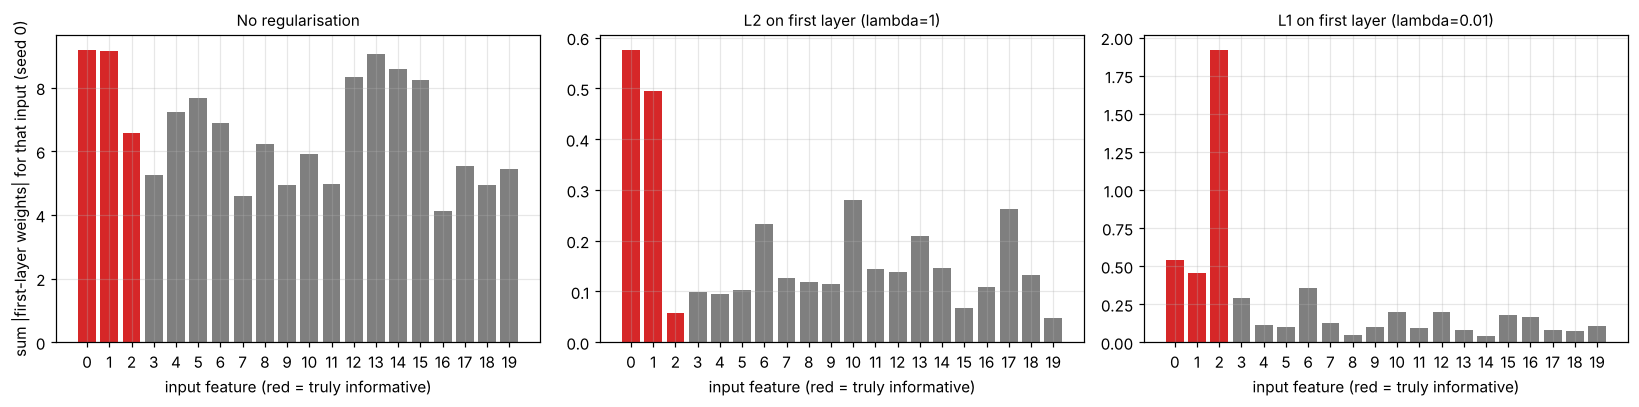

In [10]:
sel = [("No regularisation", fbase[0]["imp"]),
       (f"L2 on first layer (lambda={fbest['l2']:g})", fsweep[("l2", fbest["l2"])][0]["imp"]),
       (f"L1 on first layer (lambda={fbest['l1']:g})", fsweep[("l1", fbest["l1"])][0]["imp"])]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=False)
for ax, (title, imp) in zip(axes, sel):
    colors = ["tab:red" if i < 3 else "tab:gray" for i in range(20)]
    ax.bar(range(20), imp, color=colors); ax.set_xticks(range(20)); ax.set_xlabel("input feature (red = truly informative)")
    ax.set_title(title, fontsize=10)
axes[0].set_ylabel("sum |first-layer weights| for that input (seed 0)")
plt.tight_layout(); plt.show()

## Experiment 6: L2 penalty vs weight decay

"Weight decay" means shrinking each weight directly: `w <- w - eta (grad + wd * w)`. For plain SGD this is **identical** to adding an L2 penalty: PyTorch's `weight_decay = wd` equals a penalty `(wd/2) ||w||^2`. For adaptive optimizers like Adam it is **not** identical, because Adam rescales the penalty gradient along with the data gradient. **AdamW** decouples the decay from the gradient, which restores the "shrink every weight by the same fraction" behaviour.

We check all three numerically on a tiny model by comparing the final weights.

In [11]:
def tiny_net():
    torch.manual_seed(0)
    return nn.Sequential(nn.Linear(5, 8), nn.Tanh(), nn.Linear(8, 1))

torch.manual_seed(1)
Xe, Ye = torch.randn(32, 5), torch.randn(32, 1)

def run(opt_fn, penalty_lam=0.0, steps=200):
    net = tiny_net(); opt = opt_fn(net.parameters())
    for _ in range(steps):
        opt.zero_grad(); loss = F.mse_loss(net(Xe), Ye)
        if penalty_lam:
            loss = loss + penalty_lam * sum((p ** 2).sum() for p in net.parameters())
        loss.backward(); opt.step()
    return torch.cat([p.flatten() for p in net.parameters()]).detach()

sgd_wd   = run(lambda p: torch.optim.SGD(p, lr=0.05, weight_decay=0.02))
sgd_pen  = run(lambda p: torch.optim.SGD(p, lr=0.05), penalty_lam=0.01)
adam_wd  = run(lambda p: torch.optim.Adam(p, lr=0.01, weight_decay=0.02))
adam_pen = run(lambda p: torch.optim.Adam(p, lr=0.01), penalty_lam=0.01)
adamw    = run(lambda p: torch.optim.AdamW(p, lr=0.01, weight_decay=0.02))
none     = run(lambda p: torch.optim.Adam(p, lr=0.01))

maxdiff = lambda a, b: (a - b).abs().max().item()
print(f"SGD(weight_decay=0.02)  vs SGD + 0.01*||w||^2 penalty : max |diff| = {maxdiff(sgd_wd, sgd_pen):.1e}   (same thing)")
print(f"Adam(weight_decay=0.02) vs Adam + 0.01*||w||^2 penalty: max |diff| = {maxdiff(adam_wd, adam_pen):.1e}   (same thing: both are an L2 penalty)")
print(f"Adam(weight_decay=0.02) vs AdamW(weight_decay=0.02)   : max |diff| = {maxdiff(adam_wd, adamw):.2f}   (different algorithms)")
print(f"final ||w||_2: no decay {none.norm():.2f} | Adam+L2 {adam_wd.norm():.2f} | AdamW {adamw.norm():.2f}")

SGD(weight_decay=0.02)  vs SGD + 0.01*||w||^2 penalty : max |diff| = 8.9e-08   (same thing)
Adam(weight_decay=0.02) vs Adam + 0.01*||w||^2 penalty: max |diff| = 2.3e-06   (same thing: both are an L2 penalty)
Adam(weight_decay=0.02) vs AdamW(weight_decay=0.02)   : max |diff| = 1.74   (different algorithms)
final ||w||_2: no decay 6.46 | Adam+L2 4.09 | AdamW 6.41


## 7. Practical notes

- **Choose `lambda` on validation data,** on a log grid, and plot train/val error against it (Experiment 2). Too small does nothing; too large underfits (training error rises).
- **`lambda` is relative to the loss scale.** It matters whether the data term is a mean or a sum over the batch, and what units the target has. A value from another project does not transfer.
- **Penalise weight matrices, not biases** (and usually not normalisation scale/shift parameters). We did exactly that here.
- **Use AdamW, not Adam with `weight_decay`,** when you want weight decay with an adaptive optimizer (Experiment 6).
- **L1 needs care to get exact zeros.** A plain penalty gives many tiny weights; for real sparsity use a proximal step (Experiment 4) or prune small weights afterwards (magnitude pruning, not tested here).
- **L1 and L2 can be combined** (elastic net): `lambda1 ||w||_1 + lambda2 ||w||^2`.
- **Regularisers are not the only tool.** Early stopping, dropout, data augmentation and more data also reduce overfitting; in Experiment 4 the unregularised SGD run ended with a higher training error than Adam (0.043 vs 0.003) and a much lower test error (0.136 vs 0.308), which is consistent with shorter optimisation acting as an implicit regulariser.

## Summary

Numbers are from this notebook's executed run (fixed seeds; 5 seeds in Experiments 2 and 5, 3 seeds in Experiment 4, seed 0 in Experiment 3).

| Experiment | What we measured | Result |
|---|---|---|
| 1 | One weight, then two weights | L2 scales every weight down; L1 subtracts and clips. In the 2D example, L1 sets `w2` to exactly 0 from lambda = 1.4 onward (while `w1` is still 1.16); L2 never reaches 0 (smallest `w2` on the path is 0.32) |
| 2 | 30 noisy points, MLP with 64x64 tanh units | No regularisation: train MSE 0.010, test 0.283 (noise floor 0.09). L2 (lambda 0.01, chosen on validation): test 0.108. L1 (lambda 0.001): test 0.120. Too strong underfits: L2 at 0.1 gives train 0.193 / test 0.222, L1 at 0.1 gives train 0.150 / test 0.173. L2 is slightly ahead of L1, but the gap is within the seed-to-seed spread |
| 3 | Weights of the seed-0 networks (Adam) | L2 norm of all weights: 23.5 without regularisation, 2.1 with L2, 4.9 with L1. L1 norm: 822, 57 with L2, 16 with L1. Each penalty shrinks its own norm the most. Weights below 1e-3: 8.9% (L2) vs 60.7% (L1); none exactly 0 |
| 4 | Same model, three optimizers (3 seeds, fixed lambda) | SGD+momentum: L2 (1e-3) test 0.106 with 2.6% of weights tiny; L1 (1e-3) test 0.109 with 98.5% tiny. Adam: L2 54.5% tiny vs L1 58.7% tiny. Only the proximal step gave **exact** zeros: 46% (lambda 1e-3, test 0.107) and 95% (3e-3, test 0.122) |
| 5 | 20 inputs, 3 useful, first-layer penalty | Test MSE: none 0.983, L2 0.786, L1 0.372 (lambda chosen on validation). With the validation-chosen lambda, L1 ranks all 3 true features on top in 3 of 5 seeds (4 of 5 at lambda 0.001), L2 in 1 of 5 (3 of 5 at lambda 0.001) |
| 6 | Penalty vs optimizer weight decay | SGD `weight_decay` equals an L2 penalty (max weight difference 9e-8); so does Adam `weight_decay` (2e-6); AdamW is a different algorithm (difference 1.74). With the same nominal 0.02, the final L2 norm of the weights was 4.09 (Adam + L2), 6.41 (AdamW) and 6.46 (no decay) |

**Takeaways**

1. Both penalties fix the overfitting here (test MSE 0.283 down to about 0.11 to 0.12), and both need `lambda` tuned: too small does nothing, too large underfits.
2. On plain accuracy, L1 and L2 were close in this task. L1 clearly won when many inputs were irrelevant (test MSE 0.37 vs 0.79 in Experiment 5).
3. "L1 gives sparse weights, L2 does not" is only partly true in a neural network. With SGD, at about the same test error, L1 left 98.5% of weights tiny versus 2.6% for L2. With Adam both left roughly half of the weights tiny. Exact zeros appeared only with a proximal step. When you report sparsity, say which optimizer you used and count exact zeros separately from tiny weights.
4. L2 penalty and weight decay are the same thing for SGD but not for Adam. Use AdamW for decoupled decay, and do not carry a `lambda` or `weight_decay` number from one optimizer to another.
5. L1 feature selection is useful but imperfect: it found all 3 true features in 3 of 5 seeds at the validation-chosen `lambda`.

These are small toy problems with few seeds, and the Experiment 4 `lambda` values were fixed rather than tuned, so treat the comparisons as demonstrations of behaviour, not benchmarks.

**Discussion questions**

1. Why does the L1 path in the 2D plot reach an axis while the L2 path does not? (Think about the size of the pull toward zero as a weight gets small.)
2. In Experiment 3 the L1 network has a larger L2 norm than the L2 network, but a much smaller L1 norm. Why?
3. In Experiment 2 the test errors of L1 and L2 are close even though the weights look very different. What does that say about using weight sparsity as a goal in itself?
4. In Experiment 5, which of the three true features is hardest to detect, and how would you check your guess?
5. Why is it a problem to compare optimizers at the same `weight_decay` number?